
# Homogeneous Linear Difference Equations

## The Homogeneous Equation

They describe how a variable evolves over time (laws of motion). They are widely used in economics, finance, biology, and many other fields
because in a lot of application it is easier to think about how a variable changes from one period to the next rather than thinking about its absolute value.
The example of the bank account that we studied in the previous chapter is a simple example of a first order linear difference equation.
We saw last quite easy to describe the value of the bank account in a given month as a function of the value of the bank account in the previous month plus interest (assuming no deposits or withdrawals):

:::{.ex-class}
$$
x_{t} = (1 + 0.02) x_{t - 1}
$$
:::

However it required more work to express the value of the bank account in month $t$ as
a function of the initial value of the bank account ($x_0$) and the time index $t$ (in other words to solve the equation):

$$
x_t = (1.02)^t x_0 
$$

In order to study how this systems described by an equation of this form move over time it helps to generalize the equation a bit. We will replace the specific number $1.02$ with a more general parameter $\phi$  and see what happens
for different values of $\phi$. Basically we will repeat the analysis that we did last time but with a few different values of $\phi$.

$$
x_t = \phi^{t} x_{0}
$$

To visualize the process for a single choice of $\phi$ and the initial value $x_0$ we only need to plug the concrete values in the formula above. For example, if $\phi = 0.8$ and $x_0 = 10$ then we have:

$$
x_t = 10 \cdot 0.8^t 
$$

Now set $t$ to 0, 1, 2, etc. to see how the value of $x_t$ evolves over time.

| $t$  | $x_t$    |
|----|--------|
| 0  | $10 \cdot 0.8^{0} = 10.0$ |
| 1  | $10 \cdot 0.8^{1} = 8.0$  |
| 2  | $10 \cdot 0.8^{2} = 6.4$  |
| 3  | $10 \cdot 0.8^{3} = 5.1$  |
| 4  | $10 \cdot 0.8^{4} = 4.1$  |
| 5  | $10 \cdot 0.8^{5} = 3.3$  |
| 6  | $10 \cdot 0.8^{6} = 2.6$  |
| 7  | $10 \cdot 0.8^{7} = 2.1$  |
| 8  | $10 \cdot 0.8^{8} = 1.7$  |


Now we want to do the same using `numpy` and `matplotlib` (to visualize the results).


In [ ]:
#ex-class

import numpy as np
import matplotlib.pyplot as plt

# Set the number of periods to simulate (we want to be able to change it later)
T = 20

# Create a sequence of values for t running from 0 to T-1, e.g. t = [0, 1, 2, ..., 19] in our case when T = 20
t = np.arange(T)

# Print the sequence to check that it is correct
# Compare the values with the manual calculation in the table above
# to see that they are the same (up to rounding in the table)

print(t)


[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19]


In [ ]:
#ex-class

# Now compute the formula for x_t (** means exponentiation, a single * means multiplication)

phi = 0.8
x_0 = 10

x_t = x_0 * phi**t

# Print the results
print(x_t)


[10.          8.          6.4         5.12        4.096       3.2768
  2.62144     2.097152    1.6777216   1.34217728  1.07374182  0.85899346
  0.68719477  0.54975581  0.43980465  0.35184372  0.28147498  0.22517998
  0.18014399  0.14411519]


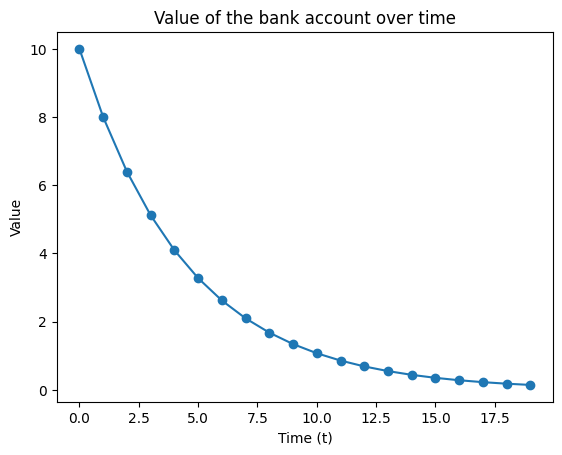

In [ ]:
#ex-class

# Now plot the value of x_t (y-axis) against t (x-axis)
plt.plot(t, x_t, marker="o")

# Add a title to the plot and labels to the axes
plt.title("Value of the bank account over time")
plt.xlabel("Time (t)")
plt.ylabel("Value")

# Show the plot
plt.show()


## Convergence

Our primary interest here is to see how the value of $x_t$ evolves over time for different values of $\phi$ and $x_0$.

As an exercise, try changing the value of $\phi$ and see what happens to the behavior of the system (look at how the plot changes). Also try changing the initial value $x_0$ and see what happens to the behavior of the system. You will notice that for values of $\phi$ that are between 0 and 1 the sequence of values goes down to zero when $t$ becomes large. The values also go down to zero for $-1< \phi < 0$ but in this case the sign of the values changes from minus to plus and back again. This is because odd powers of negative numbers are negative and even powers are positive.

For values of $\phi$ greater than 1 the values of $x_t$ go to infinity.

The following plot shows the behavior of the system for different values of $\phi$ greater than 0.


In [4]:
import numpy as np
import matplotlib.pyplot as plt

t = np.arange(20)
x_0 = 10
phi = [0.8, 0.9, 0.95, 1.0, 1.005, 1.01, 1.02]

x = np.zeros((len(phi), len(t)))

for i in range(len(phi)):
    x[i, :] = x_0 * phi[i]**t

# Uncomment the print statement to see what is in x
# You should see a matrix with as many rows as there
# are different phi values (7) and as many columns as there
# are time periods (20)

# print(x)


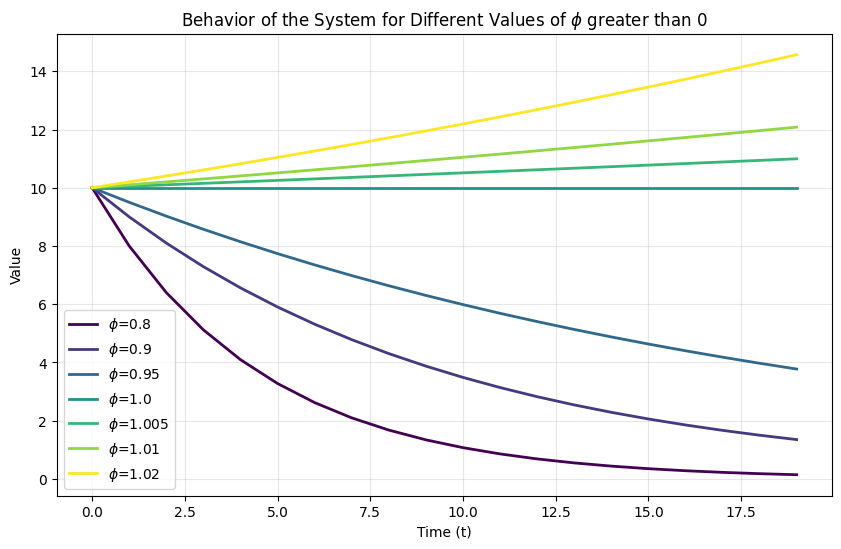

In [5]:
#| label: fig-diff-eq-homogeneous-behavior
#| fig-cap: "Behavior of the homogeneous system for different values of $\\phi$"

# Plot the results with continuous color scale

plt.figure(figsize=(10, 6))

# Create a colormap
colors = plt.cm.viridis(np.linspace(0, 1, len(phi)))

for i in range(len(phi)):
    plt.plot(t, x[i], label=fr"$\phi$={phi[i]}", color=colors[i], linewidth=2)

plt.title(r"Behavior of the System for Different Values of $\phi$ greater than 0")
plt.xlabel(r"Time (t)")
plt.ylabel(r"Value")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

From @fig-diff-eq-homogeneous-behavior you can see that $\phi = 1$ is kind of a special boundary case. It corresponds to a situation where you neither earn nor pay interest on your bank account. Assuming there are no deposits or withdrawals or service fees,
the value of your bank account will not change over time (it will stay the same as the initial value $x_0$).

However, if $\phi$ is even slightly larger than 1 (for example $\phi = 1.01$) then the value of your bank account will grow over time without bound (it will go to infinity as $t$ goes to infinity).
Mathematically you say that the sequence of amounts over time ($x_1, x_2, \ldots, x_t$) diverges (has no limit).

$$
\lim_{t \to \infty} x_t = \lim_{t \to \infty} \phi^t x_0 = +\infty \quad \text{for any } \phi > 1, x_0 > 0
$$

For values less of $\phi$ that are smaller than 1 (for example $\phi = 0.98$) (meaning you pay interest on your bank account, this can actually happen in some countries with negative interest rates and means that you pay the bank for holding your money)
the value of your bank account will diminish over time and eventually go to zero (it will converge to zero as $t$ goes to infinity).

$$
\lim_{t \to \infty} x_t = \lim_{t \to \infty} \phi^t x_0 = 0 \quad \text{for any } 0 < \phi < 1
$$

The next case is when $\phi$ is negative. This does not make much sense in the context of a bank account but it can be useful in other contexts.

For example if $\phi = -1.01$ then the value of your bank account will oscillate between positive and negative values and diverge (it will go to plus or minus infinity as $t$ goes to infinity).


In [6]:
phi_neg = [-0.95, -1.0, -1.01]

t_neg = np.arange(30)
x_neg = np.zeros((len(phi_neg), len(t_neg)))

for i in range(len(phi_neg)):
    x_neg[i, :] = x_0 * phi_neg[i]**t_neg

x_neg

array([[ 10.        ,  -9.5       ,   9.025     ,  -8.57375   ,
          8.1450625 ,  -7.73780937,   7.35091891,  -6.98337296,
          6.63420431,  -6.3024941 ,   5.98736939,  -5.68800092,
          5.40360088,  -5.13342083,   4.87674979,  -4.6329123 ,
          4.40126669,  -4.18120335,   3.97214318,  -3.77353603,
          3.58485922,  -3.40561626,   3.23533545,  -3.07356868,
          2.91989024,  -2.77389573,   2.63520094,  -2.5034409 ,
          2.37826885,  -2.25935541],
       [ 10.        , -10.        ,  10.        , -10.        ,
         10.        , -10.        ,  10.        , -10.        ,
         10.        , -10.        ,  10.        , -10.        ,
         10.        , -10.        ,  10.        , -10.        ,
         10.        , -10.        ,  10.        , -10.        ,
         10.        , -10.        ,  10.        , -10.        ,
         10.        , -10.        ,  10.        , -10.        ,
         10.        , -10.        ],
       [ 10.        , -10.1   

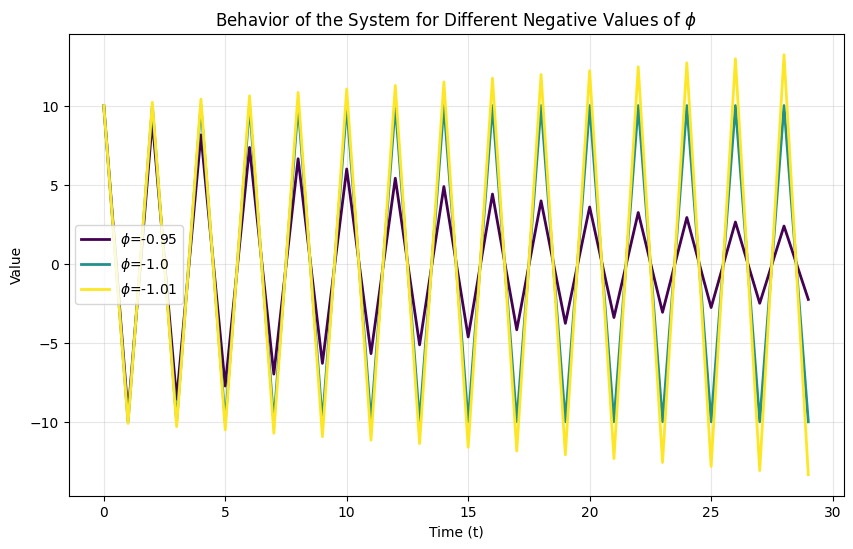

In [7]:
#| label: fig-diff-eq-homogeneous-behavior-negative
#| fig-cap: "Behavior of the Homogeneous System for Different Negative Values of $\\phi$"

# Plot the results with continuous color scale

plt.figure(figsize=(10, 6))
# Create a colormap
colors = plt.cm.viridis(np.linspace(0, 1, len(phi_neg)))
for i in range(len(phi_neg)):
    plt.plot(t_neg, x_neg[i], label=fr"$\phi$={phi_neg[i]}", color=colors[i], linewidth=2)

plt.title(r"Behavior of the System for Different Negative Values of $\phi$")
plt.xlabel(r"Time (t)")
plt.ylabel(r"Value")
plt.legend()
plt.grid(alpha=0.3)

From @fig-diff-eq-homogeneous-behavior-negative you can see that $\phi = -1$ is also a quite special boundary case.
Because taking an even power (e.g. $(-1)^2 = 1$) of a negative number gives a positive result and taking an odd power (e.g. $(-1)^3 = (-1)\times (-1) \times (-1) = -1 $) of a negative number gives a negative result,
the value of your bank account will flip from $x_0$ in even months to $-x_0$ in odd months.

Again, for values of $\phi$ that are slightly smaller than -1 (for example $\phi = -1.01$) the value of your bank account will oscillate between positive and negative values and diverge (it will go to plus or minus infinity as $t$ goes to infinity).

Only for $0 < \phi < -1$ does the value go to zero as $t$ goes to infinity (again, in an oscillating manner).

$$
\lim_{t \to \infty} x_t = \lim_{t \to \infty} \phi^t x_0 = 0 \quad \text{for any } -1 < \phi < 0
$$


We can also pose a related question. What happens with the system if we change the initial value $x_0$? In other words
we can ask: what is the effect of a small change in the initial value $x_0$ after a long time (as $t$ goes to infinity)?

Again, the answer depends on the value of $\phi$. Let's compare three scenarios: $\phi = 0.9$, $\phi = 1$, and $\phi = 1.1$.
In each case we will compare the trajectories of the system for two different initial values $x_0 = 100$ and $x_0 = 105$.

First let's do this on paper for the first case:

$$
\begin{align*}
x_t^{*} = \phi^t (x_0 + 5) = \phi^t x_0 + 5 \phi^t = x_t + 5 \phi^t \\
\end{align*}
$$

So the difference between the two trajectories is

$$
x_t^{*} - x_t = 5 \phi^t
$$

It is easy to see from this expression that for $\phi = 0.9$ the difference goes to zero as $t$ time goes to infinity (the two trajectories converge to each other).
However, for $\phi = 1$ the difference stays constant at 5 (it never disappears). For $\phi = 1.1$ the difference diverges (it gets larger and larger without bound as $t$ goes to infinity).

You can also answer this question by taking the derivative of $x_t$ with respect to $x_0$:

$$
\frac{\partial x_t}{\partial x_0} = \phi^t
$$
